In [146]:
from pathlib import Path
import re
import unicodedata

import geopandas as gpd
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [147]:
# Locate pedestrian_accessibility from its folder, the urban_form root,
# or any nested notebook directory.
cwd = Path.cwd().resolve()

repo_root = next(
    path
    for path in (cwd, cwd / "pedestrian_accessibility", *cwd.parents)
    if (path / "data/input/shape").is_dir()
)

shape_dir = repo_root / "data/input/shape"
table_dir = repo_root / "data/input/table"

metric_crs = "EPSG:32618"  # Project CRS used for metric calculations

# Select one city and one equipment dimension for the complete analysis.
# City matching ignores capitalization, accents, spaces, and underscores.
selected_city = "bogota"

# Options: health, sport, education, financial, cultural, parks
selected_dimension = "education"

def normalize_city_name(value):
    ascii_value = (
        unicodedata.normalize("NFKD", str(value))
        .encode("ascii", "ignore")
        .decode("ascii")
        .casefold()
    )
    return re.sub(r"[^a-z0-9]+", "_", ascii_value).strip("_")


# Discover the available city networks from their edge-file names.
city_networks = {}

for edge_path in sorted((shape_dir / "edges").glob("*_edges.shp")):
    network_stem = edge_path.stem.removesuffix("_edges")
    city_slug, network_id = network_stem.rsplit("-", maxsplit=1)
    city_key = normalize_city_name(city_slug)

    if city_key in city_networks:
        raise ValueError(f"Duplicate normalized city name: {city_key}")

    city_networks[city_key] = {
        "slug": city_slug,
        "network_id": network_id,
        "edge_path": edge_path,
        "node_path": shape_dir / "nodes" / f"{network_stem}_nodes.shp",
    }

selected_city_key = normalize_city_name(selected_city)

if selected_city_key not in city_networks:
    available_cities = ", ".join(
        record["slug"] for record in city_networks.values()
    )
    raise ValueError(
        f"City {selected_city!r} was not found. "
        f"Available cities: {available_cities}"
    )

selected_network = city_networks[selected_city_key]
selected_edge_path = selected_network["edge_path"]
selected_node_path = selected_network["node_path"]
selected_city_label = str(selected_city).strip().replace("_", " ").title()

if not selected_node_path.exists():
    raise FileNotFoundError(
        f"Node file not found for {selected_city!r}: {selected_node_path}"
    )

equipment_codes = {
    "health": ["021001", "021002", "021003", "021004", "021011"],
    "sport": ["020601", "020602", "020603", "020604", "020605", "020606"],
    "education": ["020903", "020905"],
    "financial": ["020501", "020502"],
    "cultural": ["020701", "020702", "020706", "020709", "020710"],
    "parks": ["021101", "021102", "021104", "021105"],
}

equipment_labels = {
    "health": {"title": "Health", "singular": "health center", "plural": "health centers"},
    "sport": {"title": "Sport", "singular": "sports facility", "plural": "sports facilities"},
    "education": {"title": "Education", "singular": "educational facility", "plural": "educational facilities"},
    "financial": {"title": "Financial", "singular": "financial facility", "plural": "financial facilities"},
    "cultural": {"title": "Cultural", "singular": "cultural facility", "plural": "cultural facilities"},
    "parks": {"title": "Parks", "singular": "park", "plural": "parks"},
}

if selected_dimension not in equipment_codes:
    raise ValueError(
        f"Unknown dimension {selected_dimension!r}. "
        f"Choose one of: {', '.join(equipment_codes)}"
    )

selected_codes = equipment_codes[selected_dimension]
selected_label = equipment_labels[selected_dimension]

print(f"Selected city: {selected_city_label}")
print(f"Network ID: {selected_network['network_id']}")
print(f"Selected dimension: {selected_label['title']}")
print(f"CSIMBOL codes: {', '.join(selected_codes)}")

Selected city: Bogota
Network ID: 621
Selected dimension: Education
CSIMBOL codes: 020903, 020905


In [148]:
# Urban perimeters for Colombia
all_perimeters = gpd.read_file(
    shape_dir
    / "Colombia_urban_perimeters_name_pop"
    / "Colombia_urban_perimeters_name_pop.shp"
).to_crs(metric_crs)

# Pedestrian-network edges for the selected city
edges = gpd.read_file(selected_edge_path).to_crs(metric_crs)

# Find every urban perimeter intersected by this regional network
network_perimeter_matches = gpd.sjoin(
    edges[["geometry"]],
    all_perimeters[["ID_mpio", "Name", "geometry"]],
    how="inner",
    predicate="intersects",
)

metro_units = all_perimeters[
    all_perimeters["ID_mpio"].isin(
        network_perimeter_matches["ID_mpio"].unique()
    )
].copy()

# Dissolve the intersected urban perimeters into one analysis geometry
metro_perimeter = gpd.GeoDataFrame(
    {"geometry": [metro_units.geometry.union_all()]},
    crs=metric_crs,
)

metro_units[
    ["ID_mpio", "Name"]
].drop_duplicates().sort_values("Name")

,ID_mpio,Name
337,11001,"BOGOTA, D.C."
1017,25286,FUNZA
994,25430,MADRID
1019,25473,MOSQUERA
1128,25754,SOACHA


In [149]:
all_blocks = gpd.read_file(
    shape_dir / "MANZANA" / "MGN_URB_MANZANA.shp"
).to_crs(metric_crs)

blocks = (
    gpd.sjoin(
        all_blocks,
        metro_perimeter,
        how="inner",
        predicate="intersects",
    )
    .drop(columns="index_right")
    .drop_duplicates(subset="MANZ_CCNCT")
    .reset_index(drop=True)
)

print(f"{selected_city_label} area blocks: {len(blocks):,}")
blocks.head()

Bogota area blocks: 49,343


,MANZ_CCNCT,geometry
0,1100110000000011010101,"POLYGON ((601842.197 506811.99, 601858.732 507..."
1,1100110000000011010102,"POLYGON ((601933.212 506955.495, 602054.452 50..."
2,1100110000000011010103,"POLYGON ((602059.027 506746.604, 602117.954 50..."
3,1100110000000011010104,"POLYGON ((601820.85 506786.809, 601773.658 506..."
4,1100110000000011010105,"POLYGON ((602122.835 506648.37, 602161.157 506..."


In [150]:
# DANE 2018 demographic indicators by census block
block_stats = pd.read_csv(
    table_dir / "DANE_2018_personas_manz.txt",
    dtype={"MANZ_CCNCT": "string"},
)

# Match identifier types before attaching the indicators to the geometries
blocks["MANZ_CCNCT"] = blocks["MANZ_CCNCT"].astype("string")
blocks = blocks.merge(
    block_stats,
    on="MANZ_CCNCT",
    how="left",
    validate="one_to_one",
)

# EPSG:32618 uses metres, so convert block area from m2 to km2
blocks["area_km2"] = blocks.geometry.area / 1_000_000
blocks["pop_density_km2"] = (
    blocks["poblacion"] / blocks["area_km2"]
)

print(f"Blocks with population data: {blocks['poblacion'].notna().sum():,} / {len(blocks):,}")
blocks[
    [
        "MANZ_CCNCT",
        "poblacion",
        "area_km2",
        "pop_density_km2",
        "mujeres",
        "edad_60mas",
        "discapacidad",
        "barreras_salud",
        "geometry",
    ]
].head()

Blocks with population data: 43,769 / 49,343


,MANZ_CCNCT,poblacion,area_km2,pop_density_km2,mujeres,edad_60mas,discapacidad,barreras_salud,geometry
0,1100110000000011010101,13.0,0.007149,1818.365659,0.538462,0.230769,0.076923,0.000000,"POLYGON ((601842.197 506811.99, 601858.732 507..."
1,1100110000000011010102,442.0,0.016740,26403.861633,0.466063,0.101810,0.110860,0.462264,"POLYGON ((601933.212 506955.495, 602054.452 50..."
2,1100110000000011010103,787.0,0.055595,14156.027110,0.526048,0.053367,0.041931,0.304348,"POLYGON ((602059.027 506746.604, 602117.954 50..."
3,1100110000000011010104,2511.0,0.032320,77692.918981,0.520908,0.100757,0.058941,0.368794,"POLYGON ((601820.85 506786.809, 601773.658 506..."
4,1100110000000011010105,224.0,0.005506,40681.624417,0.477679,0.174107,0.098214,0.200000,"POLYGON ((602122.835 506648.37, 602161.157 506..."


In [151]:
nodes = gpd.read_file(selected_node_path).to_crs(metric_crs)

# Normalize graph identifiers
nodes["osmid"] = nodes["osmid"].astype(str)
edges["from"] = edges["from"].astype(str)
edges["to"] = edges["to"].astype(str)

# Naismith–Langmuir slope-adjusted walking speeds used by the project
speed_table = pd.read_csv(
    table_dir / "slope_velocity_data.csv",
    sep=";",
)

edges["speed_kmh"] = 0.0

for interval in speed_table.itertuples(index=False):
    in_interval = (
        (edges["grade_abs"] > interval.s1)
        & (edges["grade_abs"] <= interval.s2)
    )
    edges.loc[in_interval, "speed_kmh"] = interval.speed

# Special cases used by code/utils/analysis.py
edges.loc[edges["grade_abs"] == 0, "speed_kmh"] = 5.0
edges.loc[
    edges["grade_abs"] > speed_table["s2"].max(),
    "speed_kmh",
] = speed_table.iloc[0]["speed"]

# Walking impedance in minutes
edges["impedance_min"] = (
    edges["length"]
    / (edges["speed_kmh"] * 1_000 / 60)
)

print(f"Graph nodes: {len(nodes):,}")
print(f"Graph edges: {len(edges):,}")

edges[
    ["from", "to", "length", "grade_abs", "speed_kmh", "impedance_min"]
].head()

Graph nodes: 68,477
Graph edges: 100,587


,from,to,length,grade_abs,speed_kmh,impedance_min
0,253761879,268083093,60.727,0.000,5.000000,0.728724
1,253762005,253761879,196.641,0.015,3.529412,3.342897
2,310000063,253761879,65.355,0.000,5.000000,0.784260
3,253761882,253762016,104.489,0.010,3.529412,1.776313
4,253847647,253761882,57.490,0.017,3.529412,0.977330


In [152]:
G = nx.from_pandas_edgelist(
    edges,
    source="from",
    target="to",
    edge_attr=[
        "length",
        "grade_abs",
        "speed_kmh",
        "impedance_min",
        "geometry",
    ],
    edge_key="key",
    create_using=nx.MultiGraph(),
)

node_attributes = (
    nodes.set_index("osmid")[["elevation", "geometry"]]
    .to_dict(orient="index")
)

nx.set_node_attributes(G, node_attributes)
G.graph["crs"] = nodes.crs

print(G)

MultiGraph with 68477 nodes and 100587 edges


In [153]:
all_equipment = gpd.read_file(
    shape_dir
    / "colombia_equipments_ID"
    / "colombia_equipments_ID.shp"
).to_crs(metric_crs)

selected_facilities = all_equipment[
    all_equipment["CSIMBOL"].isin(selected_codes)
].copy()

selected_facilities = (
    gpd.sjoin(
        selected_facilities,
        metro_perimeter,
        how="inner",
        predicate="intersects",
    )
    .drop(columns="index_right")
    .reset_index(drop=True)
)

if selected_facilities.empty:
    raise ValueError(
        f"No {selected_label['plural']} were found in the "
        f"{selected_city_label} network area."
    )

print(
    f"{selected_label['plural'].capitalize()}: "
    f"{len(selected_facilities):,}"
)
selected_facilities.head()

Educational facilities: 3,479


,CSIMBOL,Type,ID,geometry
0,020903,education,020903048467,POINT (607248.544 532196.306)
1,020903,education,020903048493,POINT (602475.216 531279.879)
2,020903,education,020903048504,POINT (603870.69 530950.276)
3,020903,education,020903048505,POINT (605890.311 530887.581)
4,020903,education,020903048511,POINT (606036.577 530803.202)


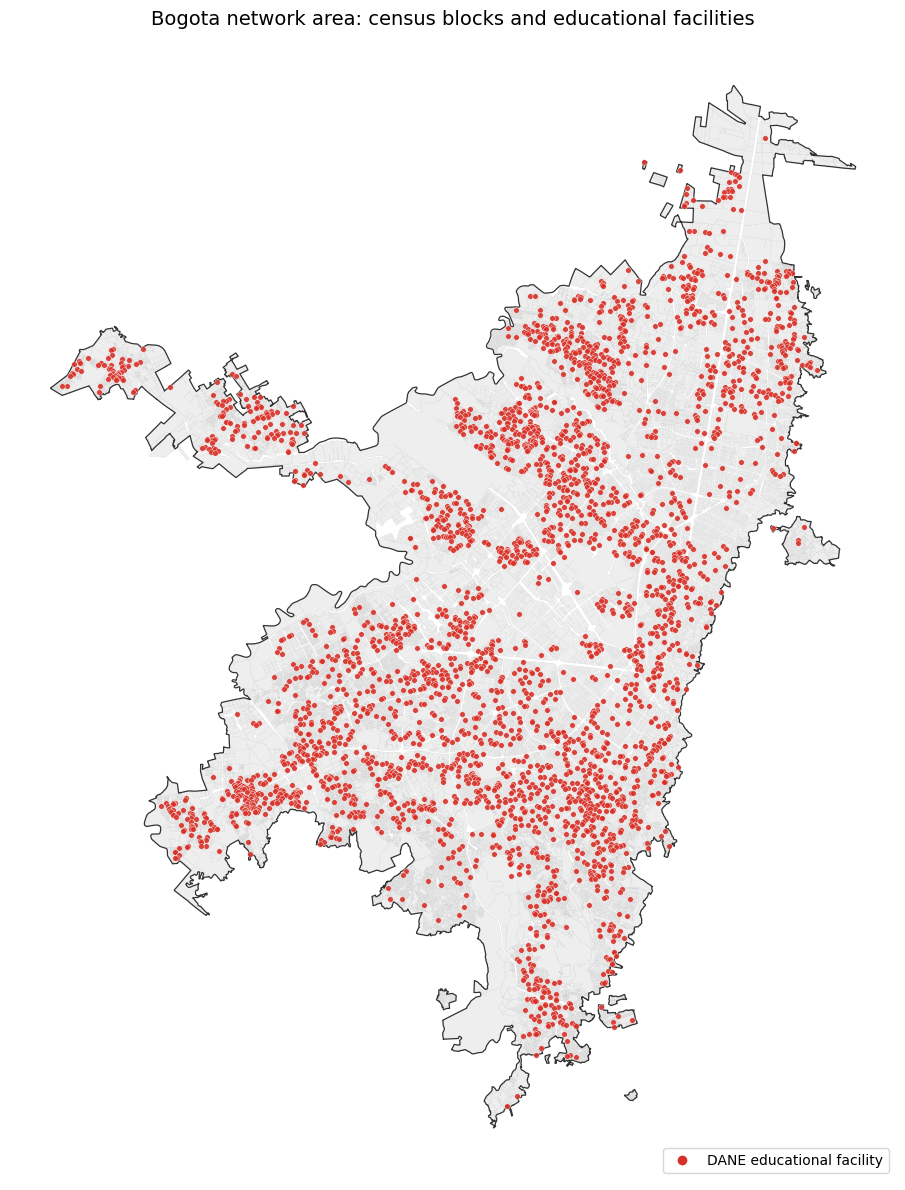

In [154]:
fig, ax = plt.subplots(figsize=(12, 12))

blocks.plot(
    ax=ax,
    facecolor="#eeeeee",
    edgecolor="#a8a8a8",
    linewidth=0.08,
)

metro_perimeter.boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.9,
)

selected_facilities.plot(
    ax=ax,
    color="#d73027",
    edgecolor="white",
    linewidth=0.3,
    markersize=16,
    alpha=0.9,
    zorder=3,
)

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="#d73027",
        markeredgecolor="white",
        markersize=8,
        label=f"DANE {selected_label['singular']}",
    )
]

ax.legend(handles=legend_elements, loc="lower right")
ax.set_title(
    f"{selected_city_label} network area: census blocks and {selected_label['plural']}",
    fontsize=14,
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [155]:
import numpy as np
import pandas as pd
import gudhi
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree


In [156]:
# ---------------------------------------------------------------
# 1. Snap each selected facility to its nearest pedestrian-network node
# ---------------------------------------------------------------

facilities = (
    selected_facilities[
        ["ID", "CSIMBOL", "geometry"]
    ]
    .copy()
    .reset_index(drop=True)
)

if facilities.crs != nodes.crs:
    facilities = facilities.to_crs(nodes.crs)

network_nodes = (
    nodes[
        ["osmid", "geometry"]
    ]
    .drop_duplicates(subset="osmid")
    .copy()
)

network_nodes["osmid"] = network_nodes["osmid"].astype(str)

# Work with the largest connected network component so every pair
# of selected network nodes has a finite travel-time distance.
largest_component = max(
    nx.connected_components(G),
    key=len,
)

network_nodes = (
    network_nodes[
        network_nodes["osmid"].isin(largest_component)
    ]
    .reset_index(drop=True)
)

walking_graph = G.subgraph(largest_component)

node_coordinates = np.column_stack(
    [
        network_nodes.geometry.x.to_numpy(),
        network_nodes.geometry.y.to_numpy(),
    ]
)

facility_coordinates = np.column_stack(
    [
        facilities.geometry.x.to_numpy(),
        facilities.geometry.y.to_numpy(),
    ]
)

node_tree = cKDTree(node_coordinates)

snap_distance_m, nearest_node_position = node_tree.query(
    facility_coordinates,
    k=1,
)

network_node_ids = network_nodes["osmid"].to_numpy()

facilities["network_node"] = (
    network_node_ids[nearest_node_position]
)

facilities["snap_distance_m"] = snap_distance_m
facilities["ph_vertex"] = np.arange(
    len(facilities),
    dtype=int,
)

facility_lookup = facilities.copy()

print(f"{selected_label['plural'].capitalize()}: {len(facilities):,}")
print(
    facilities["snap_distance_m"]
    .describe()
    .rename("Snap distance (m)")
)

Educational facilities: 3,479
count    3479.000000
mean       43.890571
std        61.549180
min         3.030057
25%        22.580430
50%        33.035982
75%        49.620366
max      1532.429788
Name: Snap distance (m), dtype: float64


In [157]:
# ---------------------------------------------------------------
# 2. Pairwise graph travel-time distance matrix
# ---------------------------------------------------------------

facility_nodes = facilities["network_node"].to_numpy()
n_facilities = len(facilities)

travel_time_matrix = np.full(
    (n_facilities, n_facilities),
    np.inf,
    dtype=float,
)

# Reuse Dijkstra results if multiple facilities snap to the same node.
dijkstra_cache = {}

for source_index, source_node in enumerate(facility_nodes):
    if source_node not in dijkstra_cache:
        dijkstra_cache[source_node] = (
            nx.single_source_dijkstra_path_length(
                walking_graph,
                source=source_node,
                weight="impedance_min",
            )
        )

    shortest_times = dijkstra_cache[source_node]

    travel_time_matrix[source_index] = np.fromiter(
        (
            shortest_times[target_node]
            for target_node in facility_nodes
        ),
        dtype=float,
        count=n_facilities,
    )

np.fill_diagonal(travel_time_matrix, 0.0)

if not np.isfinite(travel_time_matrix).all():
    raise ValueError(
        "The travel-time matrix contains unreachable pairs."
    )

if not np.allclose(
    travel_time_matrix,
    travel_time_matrix.T,
):
    raise ValueError(
        "The travel-time matrix is unexpectedly asymmetric."
    )

print(
    "Maximum asymmetry:",
    np.max(
        np.abs(
            travel_time_matrix
            - travel_time_matrix.T
        )
    ),
    "minutes",
)

travel_time_df = pd.DataFrame(
    travel_time_matrix,
    index=facilities["ID"].astype(str),
    columns=facilities["ID"].astype(str),
)

travel_time_df.iloc[:5, :5]

Maximum asymmetry: 1.3642420526593924e-12 minutes


ID,020903048467,020903048493,020903048504,020903048505,020903048511
ID,,,,,
020903048467,0.000000,133.221241,106.820942,60.686280,55.915230
020903048493,133.221241,0.000000,49.674669,109.655963,104.884913
020903048504,106.820942,49.674669,0.000000,83.255664,78.484614
020903048505,60.686280,109.655963,83.255664,0.000000,4.771050
020903048511,55.915230,104.884913,78.484614,4.771050,0.000000


In [164]:
# ---------------------------------------------------------------
# 3. Vietoris-Rips persistent homology
# ---------------------------------------------------------------

# Use the complete range of observed travel times.
max_filtration_min = float(travel_time_matrix.max())
max_filtration_min = 90.0

rips_complex = gudhi.RipsComplex(
    distance_matrix=travel_time_matrix,
    max_edge_length=max_filtration_min,
)

# A two-dimensional complex is required to obtain H1 deaths:
# triangles fill and kill one-dimensional cycles.
simplex_tree = rips_complex.create_simplex_tree(
    max_dimension=2,
)

persistence = simplex_tree.persistence(
    homology_coeff_field=2,
    min_persistence=0,
)

h0_intervals = (
    simplex_tree.persistence_intervals_in_dimension(0)
)

h1_intervals = (
    simplex_tree.persistence_intervals_in_dimension(1)
)

print(f"Maximum filtration: {max_filtration_min:.2f} min")
print(f"Vertices: {simplex_tree.num_vertices():,}")
print(f"Simplices: {simplex_tree.num_simplices():,}")
print(f"H0 intervals: {len(h0_intervals):,}")
print(f"H1 intervals: {len(h1_intervals):,}")

Maximum filtration: 90.00 min
Vertices: 3,479
Simplices: 85,654,429
H0 intervals: 3,232
H1 intervals: 687


In [165]:
# ---------------------------------------------------------------
# 4. Table of H1 features
# ---------------------------------------------------------------

h1_table = pd.DataFrame(
    h1_intervals,
    columns=["birth_min", "death_min"],
)

if not h1_table.empty:
    h1_table["persistence_min"] = (
        h1_table["death_min"]
        - h1_table["birth_min"]
    )

    h1_table = (
        h1_table
        .sort_values(
            "persistence_min",
            ascending=False,
        )
        .reset_index(drop=True)
    )

h1_table.head(20)

,birth_min,death_min,persistence_min
0,59.726609,inf,inf
1,54.849748,inf,inf
2,17.082157,48.872466,31.790309
3,14.055387,45.336173,31.280786
4,12.531576,35.437284,22.905708
5,46.574421,66.830028,20.255607
6,14.190182,34.217556,20.027374
7,9.903159,28.642745,18.739586
8,22.653711,41.343243,18.689532
9,12.639925,31.211769,18.571844


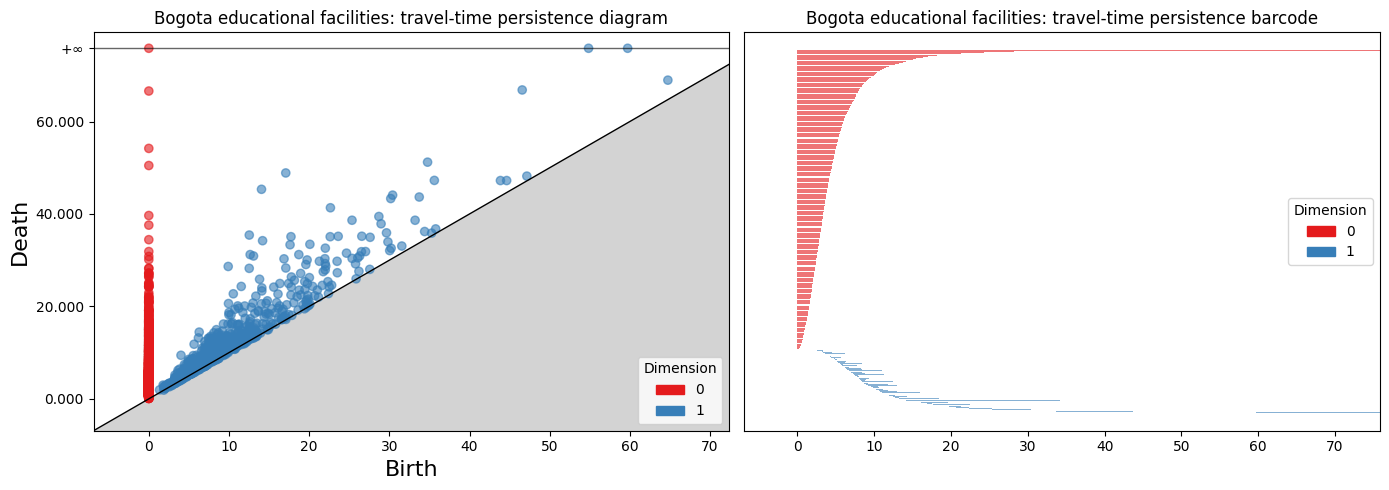

In [166]:
# ---------------------------------------------------------------
# 5. Persistence diagram and barcode
# ---------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

gudhi.plot_persistence_diagram(
    persistence,
    axes=axes[0],
)

gudhi.plot_persistence_barcode(
    persistence,
    axes=axes[1],
)

axes[0].set_title(
    f"{selected_city_label} {selected_label['plural']}: "
    "travel-time persistence diagram"
)

axes[1].set_title(
    f"{selected_city_label} {selected_label['plural']}: "
    "travel-time persistence barcode"
)

plt.tight_layout()
plt.show()

In [161]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ---------------------------------------------------------------
# Select filtration steps
# ---------------------------------------------------------------

pairwise_times = travel_time_matrix[
    np.triu_indices_from(
        travel_time_matrix,
        k=1,
    )
]

# Quantiles ensure that the panels show visibly different stages.
filtration_steps_min = np.quantile(
    pairwise_times,
    [0.005, 0.01, 0.02, 0.04, 0.08, 0.15],
)

# Alternatively, use specific travel times:
filtration_steps_min = np.array([5, 10, 15, 20, 30, 45])

print(
    "Filtration steps (minutes):",
    np.round(filtration_steps_min, 2),
)

Filtration steps (minutes): [ 5 10 15 20 30 45]


In [162]:
# ---------------------------------------------------------------
# Functions for extracting each Rips-complex snapshot
# ---------------------------------------------------------------

def get_rips_snapshot(distance_matrix, threshold):
    """
    Return all edges and triangles present at a filtration threshold.
    """

    adjacency = distance_matrix <= threshold
    np.fill_diagonal(adjacency, False)

    row_indices, column_indices = np.where(
        np.triu(adjacency, k=1)
    )

    edge_pairs = list(
        zip(
            row_indices.tolist(),
            column_indices.tolist(),
        )
    )

    neighbors = [
        set(np.flatnonzero(adjacency[vertex]))
        for vertex in range(len(adjacency))
    ]

    triangles = []

    for first, second in edge_pairs:
        common_neighbors = (
            neighbors[first]
            & neighbors[second]
        )

        for third in common_neighbors:
            # Ensures that each triangle is included once.
            if third > second:
                triangles.append(
                    (first, second, third)
                )

    return edge_pairs, triangles


def betti_at_threshold(intervals, threshold):
    """
    Number of persistence intervals alive at the given threshold.
    """

    if len(intervals) == 0:
        return 0

    intervals = np.asarray(intervals)

    alive = (
        (intervals[:, 0] <= threshold)
        & (threshold < intervals[:, 1])
    )

    return int(alive.sum())

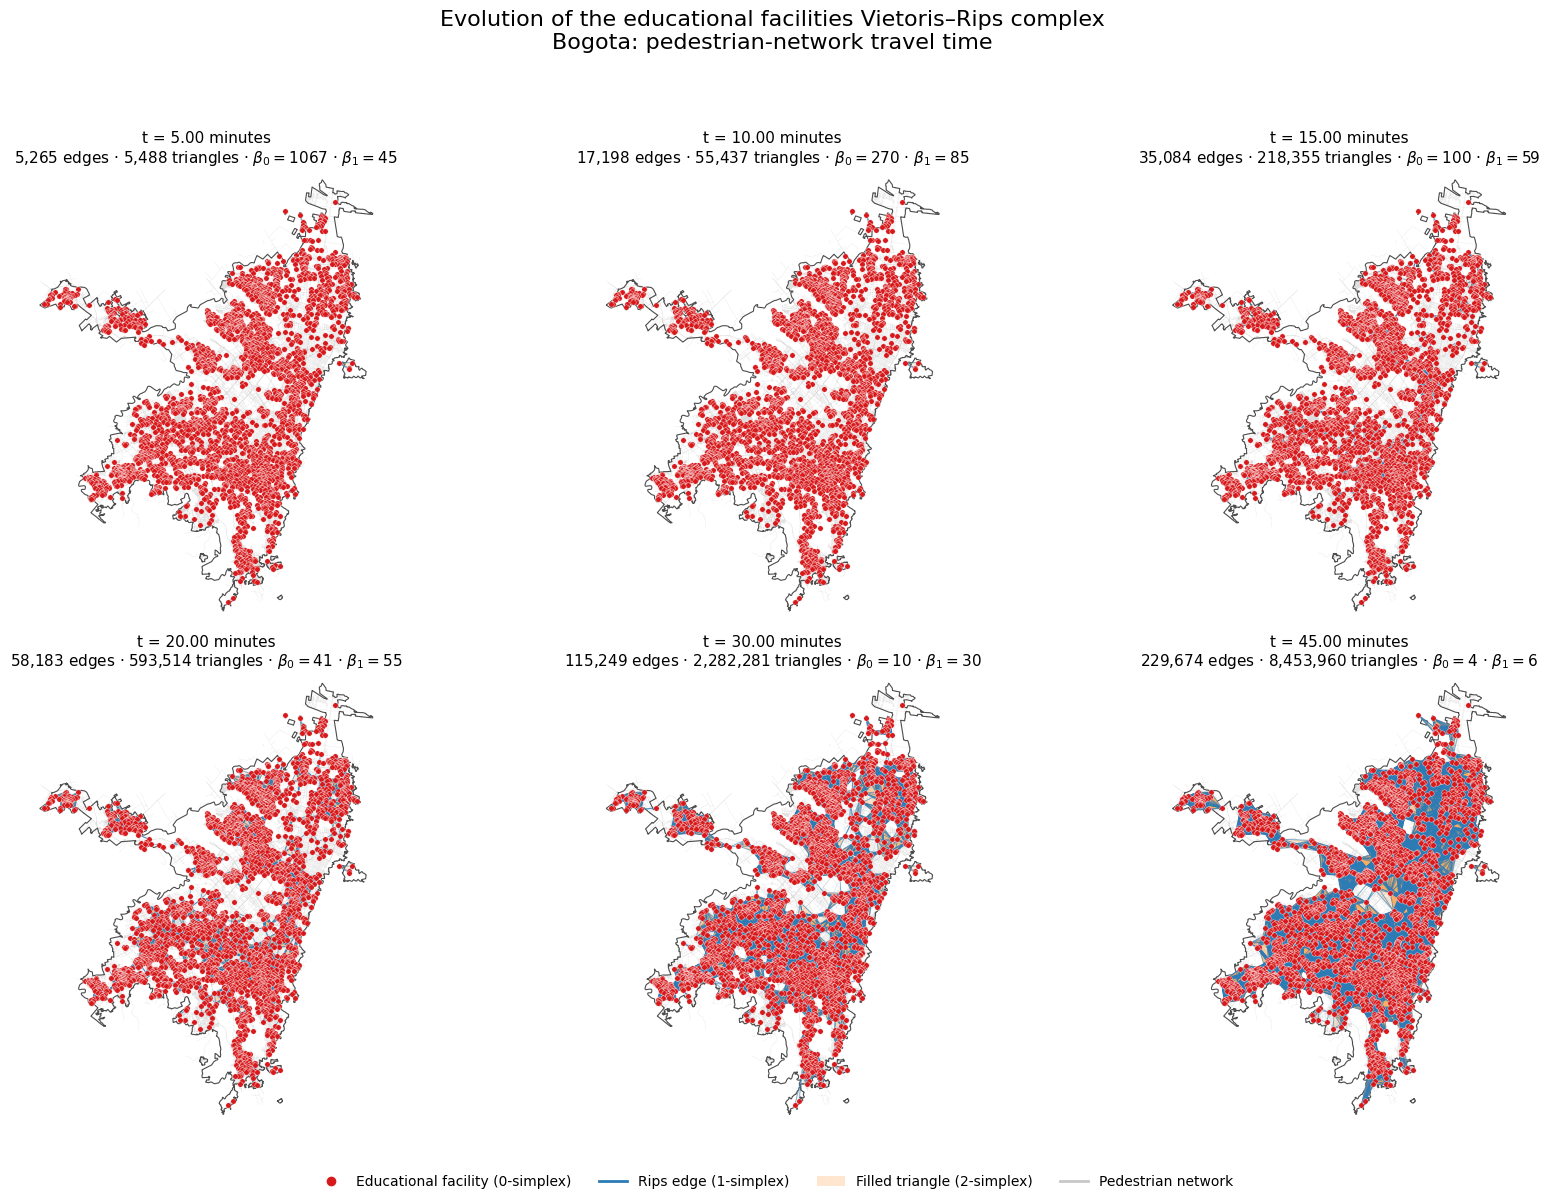

In [163]:
# ---------------------------------------------------------------
# Plot the filtration stages
# ---------------------------------------------------------------

facility_coordinates = np.column_stack(
    [
        facilities.geometry.x.to_numpy(),
        facilities.geometry.y.to_numpy(),
    ]
)

n_steps = len(filtration_steps_min)
n_columns = 3
n_rows = int(np.ceil(n_steps / n_columns))

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(18, 6 * n_rows),
    sharex=True,
    sharey=True,
)

axes = np.asarray(axes).reshape(-1)

# Use the metropolitan perimeter for consistent map limits.
xmin, ymin, xmax, ymax = metro_perimeter.total_bounds

x_margin = 0.02 * (xmax - xmin)
y_margin = 0.02 * (ymax - ymin)

for panel_index, threshold in enumerate(
    filtration_steps_min
):
    ax = axes[panel_index]

    edge_pairs, triangles = get_rips_snapshot(
        travel_time_matrix,
        threshold,
    )

    # Pedestrian-network background
    edges.plot(
        ax=ax,
        color="#c8c8c8",
        linewidth=0.25,
        alpha=0.45,
        zorder=1,
    )

    metro_perimeter.boundary.plot(
        ax=ax,
        color="#4d4d4d",
        linewidth=0.8,
        zorder=2,
    )

    # Draw two-dimensional simplices first.
    if triangles:
        triangle_indices = np.asarray(
            triangles,
            dtype=int,
        )

        triangle_polygons = facility_coordinates[
            triangle_indices
        ]

        triangle_collection = PolyCollection(
            triangle_polygons,
            facecolor="#fdae61",
            edgecolor="none",
            alpha=0.12,
            zorder=3,
        )

        ax.add_collection(triangle_collection)

    # Draw one-dimensional simplices.
    if edge_pairs:
        edge_indices = np.asarray(
            edge_pairs,
            dtype=int,
        )

        edge_segments = facility_coordinates[
            edge_indices
        ]

        edge_collection = LineCollection(
            edge_segments,
            colors="#2c7bb6",
            linewidths=0.7,
            alpha=0.6,
            zorder=4,
        )

        ax.add_collection(edge_collection)

    # Draw zero-dimensional simplices.
    ax.scatter(
        facility_coordinates[:, 0],
        facility_coordinates[:, 1],
        s=15,
        color="#d7191c",
        edgecolor="white",
        linewidth=0.25,
        zorder=5,
    )

    beta_0 = betti_at_threshold(
        h0_intervals,
        threshold,
    )

    beta_1 = betti_at_threshold(
        h1_intervals,
        threshold,
    )

    ax.set_title(
        f"t = {threshold:.2f} minutes\n"
        f"{len(edge_pairs):,} edges · "
        f"{len(triangles):,} triangles · "
        rf"$\beta_0={beta_0}$ · "
        rf"$\beta_1={beta_1}$",
        fontsize=11,
    )

    ax.set_xlim(
        xmin - x_margin,
        xmax + x_margin,
    )

    ax.set_ylim(
        ymin - y_margin,
        ymax + y_margin,
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

# Hide unused panels.
for panel_index in range(n_steps, len(axes)):
    axes[panel_index].set_visible(False)

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="#d7191c",
        markeredgecolor="white",
        markersize=8,
        label=f"{selected_label['singular'].capitalize()} (0-simplex)",
    ),
    Line2D(
        [0],
        [0],
        color="#2c7bb6",
        linewidth=2,
        label="Rips edge (1-simplex)",
    ),
    Patch(
        facecolor="#fdae61",
        alpha=0.3,
        label="Filled triangle (2-simplex)",
    ),
    Line2D(
        [0],
        [0],
        color="#c8c8c8",
        linewidth=2,
        label="Pedestrian network",
    ),
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.suptitle(
    f"Evolution of the {selected_label['plural']} Vietoris–Rips complex\n"
    f"{selected_city_label}: pedestrian-network travel time",
    fontsize=16,
    y=0.99,
)

plt.tight_layout(
    rect=[0, 0.05, 1, 0.95],
)

plt.show()

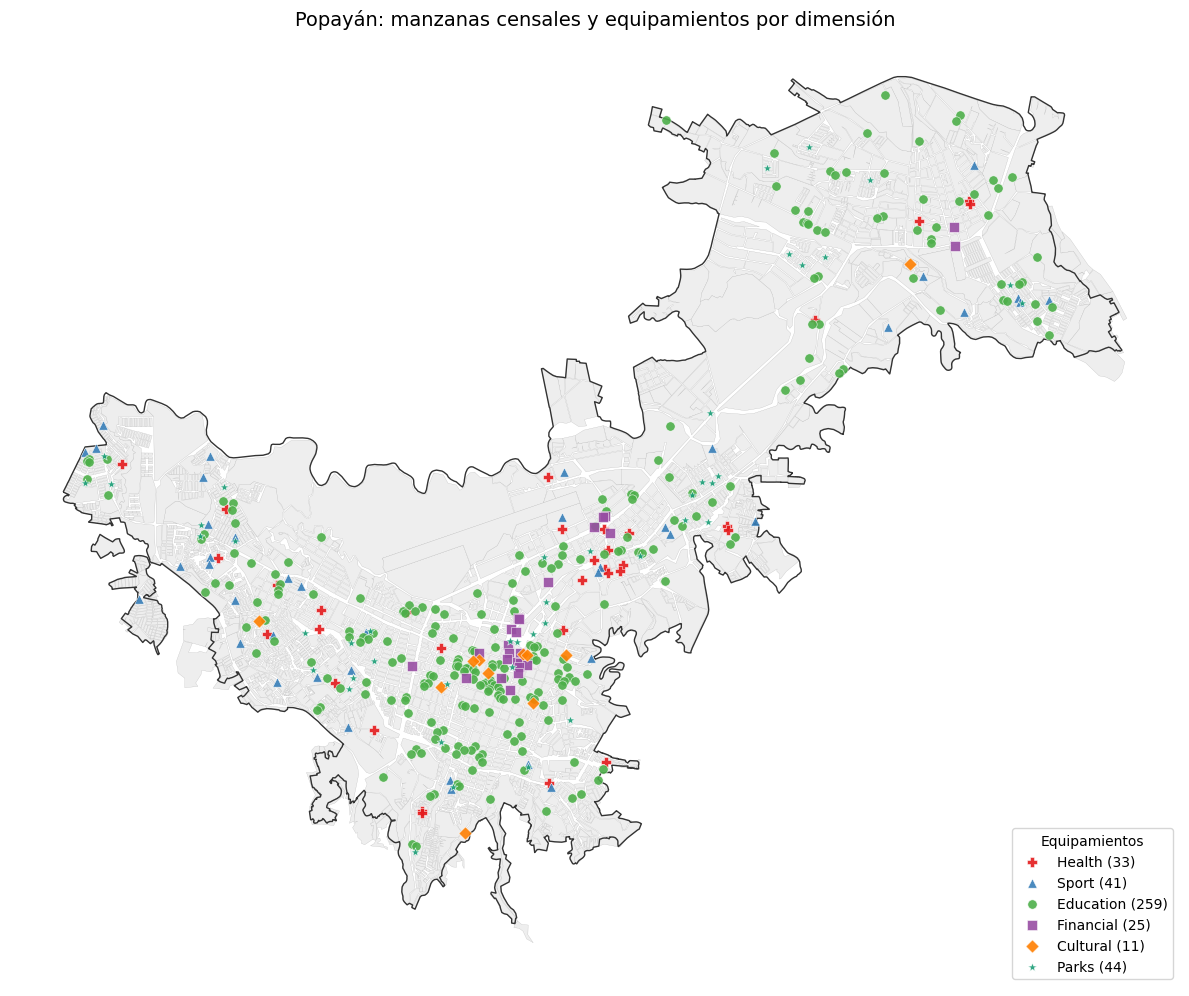

In [2]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

# --- Rutas y CRS (igual que el notebook) ---
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, cwd / "pedestrian_accessibility", *cwd.parents)
    if (path / "data/input/shape").is_dir()
)
shape_dir = repo_root / "data/input/shape"
metric_crs = "EPSG:32618"

city_edges_path = shape_dir / "edges" / "popayan-506_edges.shp"

equipment_codes = {
    "health":    ["021001", "021002", "021003", "021004", "021011"],
    "sport":     ["020601", "020602", "020603", "020604", "020605", "020606"],
    "education": ["020903", "020905"],
    "financial": ["020501", "020502"],
    "cultural":  ["020701", "020702", "020706", "020709", "020710"],
    "parks":     ["021101", "021102", "021104", "021105"],
}
styles = {
    "health":    {"color": "#e41a1c", "marker": "P"},
    "sport":     {"color": "#377eb8", "marker": "^"},
    "education": {"color": "#4daf4a", "marker": "o"},
    "financial": {"color": "#984ea3", "marker": "s"},
    "cultural":  {"color": "#ff7f00", "marker": "D"},
    "parks":     {"color": "#1b9e77", "marker": "*"},
}

# --- Perímetro urbano de Popayán (perímetros que toca su red peatonal) ---
all_perimeters = gpd.read_file(
    shape_dir / "Colombia_urban_perimeters_name_pop" / "Colombia_urban_perimeters_name_pop.shp"
).to_crs(metric_crs)
city_edges = gpd.read_file(city_edges_path).to_crs(metric_crs)

hit = gpd.sjoin(city_edges[["geometry"]], all_perimeters[["ID_mpio", "geometry"]],
                how="inner", predicate="intersects")
city_perimeter = gpd.GeoDataFrame(
    geometry=[all_perimeters[all_perimeters["ID_mpio"].isin(hit["ID_mpio"].unique())]
              .geometry.union_all()],
    crs=metric_crs,
)

# --- Manzanas (se leen solo las del perímetro con mask) ---
city_blocks = gpd.read_file(
    shape_dir / "MANZANA" / "MGN_URB_MANZANA.shp", mask=city_perimeter
).to_crs(metric_crs)
city_blocks = city_blocks[city_blocks.intersects(city_perimeter.geometry.iloc[0])]

# --- Equipamientos dentro del perímetro ---
city_equipment = gpd.read_file(
    shape_dir / "colombia_equipments_ID" / "colombia_equipments_ID.shp", mask=city_perimeter
).to_crs(metric_crs)
city_equipment = city_equipment[city_equipment.within(city_perimeter.geometry.iloc[0])]

# --- Mapa único ---
fig, ax = plt.subplots(figsize=(12, 12))
city_blocks.plot(ax=ax, facecolor="#eeeeee", edgecolor="#a8a8a8", linewidth=0.15, zorder=1)
city_perimeter.boundary.plot(ax=ax, color="#333333", linewidth=1.0, zorder=2)

for dim, codes in equipment_codes.items():
    pts = city_equipment[city_equipment["CSIMBOL"].isin(codes)]
    ax.scatter(
        pts.geometry.x, pts.geometry.y,
        s=45, c=styles[dim]["color"], marker=styles[dim]["marker"],
        edgecolors="white", linewidths=0.4, alpha=0.9, zorder=3,
        label=f"{dim.capitalize()} ({len(pts)})",
    )

ax.legend(loc="lower right", title="Equipamientos", frameon=True)
ax.set_title("Popayán: manzanas censales y equipamientos por dimensión", fontsize=14)
ax.set_aspect("equal")
ax.set_axis_off()
plt.tight_layout()
plt.savefig('popayan_todo.pdf')
plt.show()
